# 2 · Suppliers — who could hurt us, and how badly

Two sources of evidence, deliberately fused rather than chosen between.

The **questionnaire** covers everyone, including suppliers no scanner has heard of —
the crane OEM, the local integrator — but it is self-reported and static. **Public
signals** (EPSS, CISA KEV, OpenSSF Scorecard) are objective and current but only
exist where there is published software with CVEs.

Neither alone suits a small port's supplier list, which mixes global SaaS with a
two-person integrator. Together they degrade gracefully.

> The suppliers below are **illustrative roles, not real companies**. Naming real
> firms would assert things about their security this project has no evidence for.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np, pandas as pd
from portscra.viz import PALETTE, INK_MUTED, style, label_bars, despine
style()

def short(text, limit=30):
    "Trim to a word boundary — a label cut mid-word reads as a rendering bug."
    if len(text) <= limit:
        return text
    cut = text[:limit].rsplit(" ", 1)[0]
    return (cut or text[:limit]) + "…"

In [2]:
from portscra.examples import EXAMPLE_VENDORS
from portscra.vendor import CRITERIA, DEFAULT_WEIGHTS, LikelihoodModel

model = LikelihoodModel()
ranked = model.rank(EXAMPLE_VENDORS)

rows = [{"supplier": a.vendor.name, "posture": round(a.posture_score, 2),
         "signals": f"{a.signal_multiplier:.2f}x",
         "P(compromise)/yr": f"{a.annual_probability.minimum:.1%}–{a.annual_probability.maximum:.1%}",
         "most likely": a.annual_probability.most_likely,
         "coverage": f"{a.coverage:.0%}"} for a in ranked]
pd.DataFrame(rows)

,supplier,posture,signals,P(compromise)/yr,most likely,coverage
0,Crane and handling equipment OEM,0.85,1.00x,3.8%–22.6%,0.094366,100%
1,"Gate, ANPR and CCTV integrator",0.73,1.00x,3.0%–18.2%,0.075641,100%
2,Ferry booking and check-in platform,0.50,1.40x,2.8%–16.7%,0.069737,100%
3,Managed service provider (outsourced IT),0.63,1.00x,2.5%–15.1%,0.062953,100%
4,Terminal operating system vendor,0.57,1.00x,2.3%–13.6%,0.056706,100%
5,Open-source component in supplied software,0.50,1.00x,2.0%–12.0%,0.050000,0%
6,Port community system operator,0.44,1.00x,1.8%–10.8%,0.045067,100%
7,Cloud productivity and email suite,0.25,1.00x,1.3%–7.6%,0.031525,100%


## Criterion weights, elicited rather than asserted

The original brief offered teacher help with "criteria ranking". Built solo, that
elicitation became a feature instead: the tool runs the pairwise comparison with the
user and reports whether their judgements actually cohere.

AHP's consistency ratio is the part that earns its place. If someone says access
beats posture, posture beats data exposure, and data exposure beats access, the
ratio exposes the contradiction rather than quietly averaging it away.

In [3]:
from portscra.vendor import matrix_from_comparisons, weights_from_matrix

criteria = [c.key for c in CRITERIA]
judgements = {("access","posture"):3, ("access","data_exposure"):5,
              ("access","incident_history"):5, ("asset_criticality","posture"):3,
              ("asset_criticality","data_exposure"):4,
              ("asset_criticality","incident_history"):5,
              ("update_channel","posture"):2, ("update_channel","incident_history"):3,
              ("substitutability","incident_history"):2,
              ("posture","incident_history"):2, ("data_exposure","incident_history"):2}
result = weights_from_matrix(criteria, matrix_from_comparisons(criteria, judgements))

print(f"consistency ratio {result.consistency_ratio:.4f} "
      f"({'acceptable' if result.is_consistent else 'TOO INCONSISTENT'}, threshold 0.10)\n")
names = {c.key: c.name for c in CRITERIA}
for key, weight in result.ranked():
    print(f"  {names[key]:38s} {weight:.3f}   (default {DEFAULT_WEIGHTS[key]:.3f})")

consistency ratio 0.0440 (acceptable, threshold 0.10)

  Access and privilege                   0.238   (default 0.240)
  Criticality of the supplied asset      0.225   (default 0.210)
  Update and maintenance channel integrity 0.162   (default 0.170)
  Substitutability                       0.143   (default 0.100)
  Port data held by the vendor           0.094   (default 0.080)
  Vendor security posture                0.090   (default 0.140)
  Incident history and transparency      0.049   (default 0.060)


The elicited weights track the literature defaults closely — access 0.238 against a
default of 0.24. Two independent derivations landing in the same place is mild
evidence that both are reasonable.

## Live signals

Until these were fetched, every signal in this project was a hand-typed constant
labelled *illustrative*, while the README described them as fused public feeds. The
logic was real; the data was invented.

Enrichment then exposed a problem in the example data itself: the fabricated values
were **inflating** risk. One supplier carried an invented KEV hit worth 1.76×, and
live lookup dropped it to 1.00× — its assessed probability fell from 13.3% to 7.6%.
All fabricated feed values were removed, and a test now fails if one reappears.

In [4]:
from portscra.signals import fetch_epss, fetch_kev, fetch_scorecard

kev = fetch_kev()
print(f"CISA KEV: {kev.describe()} — {len(kev.data):,} known-exploited CVEs, "
      f"{sum(1 for v in kev.data.values() if v['ransomware']):,} ransomware-linked")

epss = fetch_epss(["CVE-2024-3094", "CVE-2021-44228"])
for cve, row in sorted(epss.data.items()):
    print(f"  {cve}  EPSS {row['epss']:.1%}   in KEV: {cve in kev.data}")

CISA KEV: cache, 0.6 h old — 1,656 known-exploited CVEs, 332 ransomware-linked
  CVE-2021-44228  EPSS 100.0%   in KEV: True
  CVE-2024-3094  EPSS 86.0%   in KEV: False


**This is the result worth pausing on.** CVE-2024-3094 — the xz-utils backdoor —
scores 86% on EPSS and is *absent* from CISA KEV, because it was caught before it was
exploited in the wild.

One of the most serious supply-chain compromises ever found would score **clean** on
a KEV-only check. That is exactly why the model treats KEV presence as strong
evidence and KEV absence as weak: most software never receives the scrutiny that
would put it there, and some that does is caught too early to qualify.

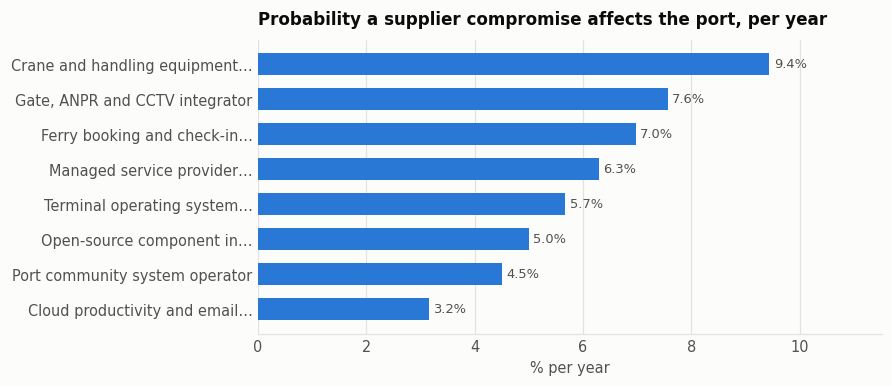

In [5]:
fig, ax = plt.subplots(figsize=(8.2, 3.6))
labels = [short(a.vendor.name) for a in ranked][::-1]
values = [a.annual_probability.most_likely * 100 for a in ranked][::-1]
bars = ax.barh(labels, values, color=PALETTE["blue"], height=0.62)
label_bars(ax, bars, values, "{:.1f}%", horizontal=True)
ax.set_title("Probability a supplier compromise affects the port, per year")
ax.set_xlabel("% per year")
ax.set_xlim(0, max(values) * 1.22)
despine(ax); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## Concentration is a property of the topology

The question a per-supplier score cannot answer: **how much of the port does each
supplier touch?** A supplier reaching everything is a concentration risk even when it
is impeccably run, and that is a fact about the dependency graph rather than about
anyone's security posture.

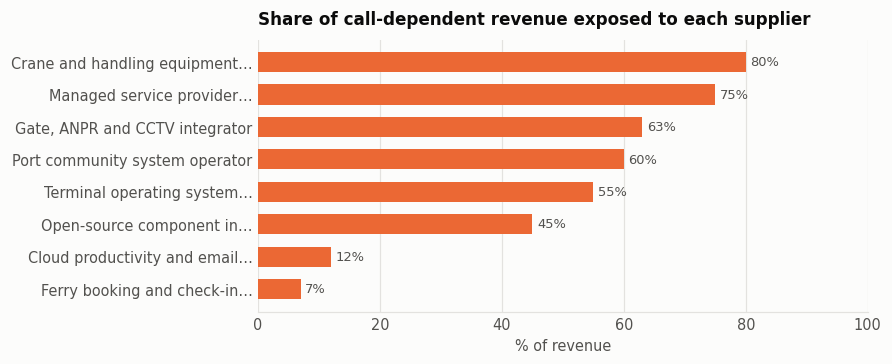

Crane and handling equipment OEM         80%  →  cargo_handling, passenger_handling, vessel_handling
Managed service provider (outsourced I   75%  →  billing, cargo_handling, declarations, gate_operations, vessel_handling
Gate, ANPR and CCTV integrator           63%  →  gate_operations, passenger_handling, vessel_handling


In [6]:
from portscra.graph import DependencyGraph

graph = DependencyGraph(EXAMPLE_VENDORS)
exposure = graph.single_points_of_failure(threshold=0.0)

fig, ax = plt.subplots(figsize=(8.2, 3.4))
labels = [short(v.name) for v, _ in exposure][::-1]
shares = [s * 100 for _, s in exposure][::-1]
bars = ax.barh(labels, shares, color=PALETTE["orange"], height=0.62)
label_bars(ax, bars, shares, "{:.0f}%", horizontal=True)
ax.set_title("Share of call-dependent revenue exposed to each supplier")
ax.set_xlabel("% of revenue")
ax.set_xlim(0, 100)
despine(ax); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

for vendor, share in exposure[:3]:
    print(f"{vendor.name[:38]:40s} {share:.0%}  →  "
          f"{', '.join(sorted(graph.services_for_vendor(vendor)))}")